In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
card1.shape, card2.shape # 두 df의 컬럼이 다른게 1개씩 있음. 

((1044710, 8), (1806800, 8))

## 범주형 EDA

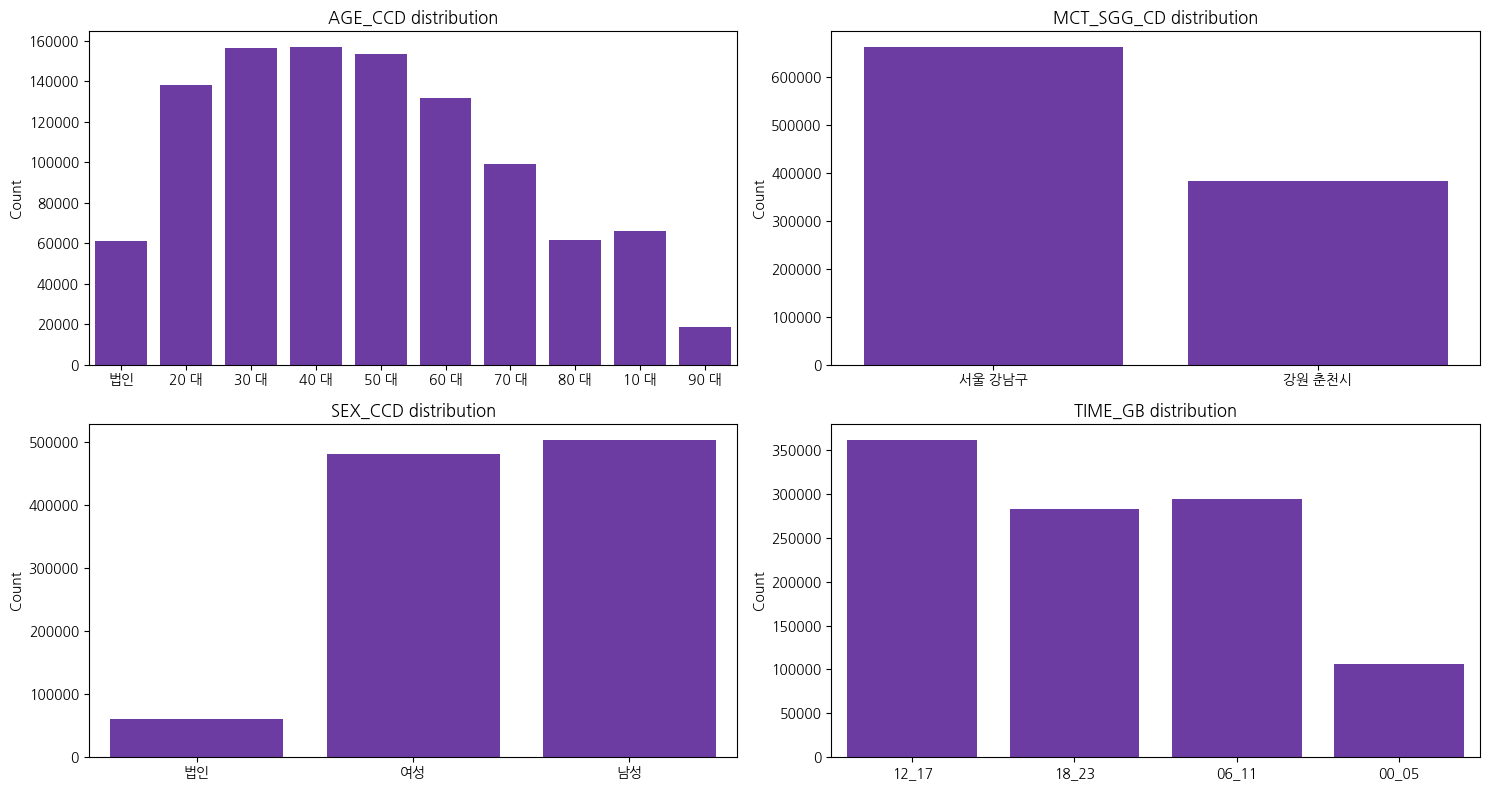

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
import math

# 한글 폰트 설정
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

plotcol = cat1col.difference(['MCT_RY_CD'])

n = len(plotcol)
ncols = 3
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 4 * nrows)
)

axes = axes.flatten()

for i, col in enumerate(plotcol):
    sns.countplot(
        data=card1,
        x=col,
        color="#6C2BB3",
        ax=axes[i]
    )

    axes[i].set_title(f"{col} distribution", fontsize=12)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Count")

# 남는 subplot 제거
for j in range(i + 1, len(axes)):
    axes[j].remove()

plt.tight_layout()
plt.show()

<Axes: ylabel='MCT_RY_CD'>

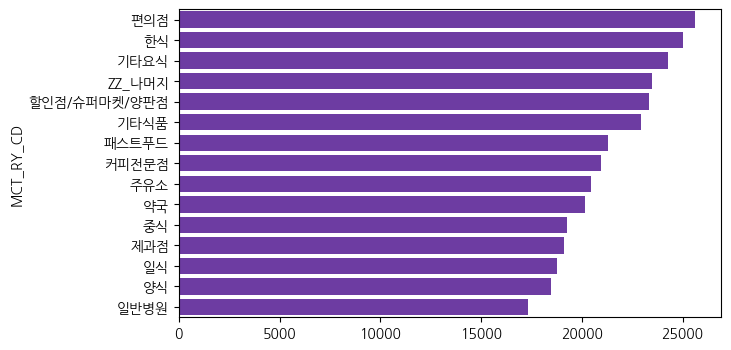

In [30]:
top10 = card1['MCT_RY_CD'].value_counts().head(15)

plt.figure(figsize=(7, 4))
sns.barplot(
    x=top10.values,
    y=top10.index,
    color="#6C2BB3"
    )


## 수치형 EDA

In [36]:
num_col = card1.select_dtypes(include = 'number').columns
card1[num_col].describe().T

,count,mean,std,min,25%,50%,75%,max
TA_YMD,1044710.0,2.025096e+07,1.716555e+02,20250701.0,20250815.0,20250930.0,20251115.0,2.025123e+07
TS_AT,1044710.0,3.433092e+07,7.705619e+08,6.0,326771.0,1666478.0,8622804.5,5.205129e+11
USE_CNT,1044710.0,5.861439e+02,2.494369e+03,5.0,12.0,41.0,187.0,7.259200e+04


## 신한카드 EDA

In [4]:
# =====================================================================
# 신한카드 빅콘테스트 2026 - EDA 공유용 코드
# 데이터1: 가맹점(강남/춘천) x 시간대 x 성별 x 연령 (법인 포함)
# 데이터2: 가맹점(강남/춘천) x 고객 거주지(시도) x 성별 x 연령 (법인 제외, 시간대 없음)
# 실행: 파일 경로(PATH)만 수정 후 위에서부터 순서대로 실행 (# %% 단위 셀)
##### 그래프에서 한글이 깨진다면 ctrl+f -> 'NanumGothic' 검색 후 'Malgun Gothic' 또는 'AppleGothic'으로 변경 ######
# =====================================================================

# %% 0. 라이브러리 & 환경설정
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 (OS별)
#plt.rcParams['font.family'] = {'Windows': 'Malgun Gothic', 'Darwin': 'AppleGothic'}.get(platform.system(), 'NanumGothic')
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
pd.options.display.float_format = '{:,.2f}'.format
sns.set_style('whitegrid')

PATH = '../data/raw/'   # <- 데이터 폴더 경로
OUT = './figs/'   # 그림 저장 폴더 (없으면 만들기)
import os; os.makedirs(OUT, exist_ok=True)

# %% 1. 데이터 로드 (탭 구분, cp949)
df1 = pd.read_csv(PATH + '신한카드_빅콘테스트2026_데이터1.txt', sep='\t', encoding='cp949')
df2 = pd.read_csv(PATH + '신한카드_빅콘테스트2026_데이터2.txt', sep='\t', encoding='cp949')

# %% 2. 기본 구조 확인
for name, df in [('데이터1', df1), ('데이터2', df2)]:
    print(f'===== {name} =====')
    print('shape:', df.shape)
    print(df.dtypes, '\n')
    print(df.head(3), '\n')
    print('결측치:', df.isna().sum().sum(), '| 중복행:', df.duplicated().sum())
    print(df[['TS_AT', 'USE_CNT']].describe(percentiles=[.01, .5, .99]).T, '\n')




===== 데이터1 =====
shape: (1044710, 8)
TA_YMD         int64
TIME_GB       object
MCT_SGG_CD    object
MCT_RY_CD     object
SEX_CCD       object
AGE_CCD       object
TS_AT          int64
USE_CNT        int64
dtype: object 

     TA_YMD TIME_GB MCT_SGG_CD MCT_RY_CD SEX_CCD AGE_CCD     TS_AT  USE_CNT
0  20250704   12_17     서울 강남구        가구      법인      법인  15477163       16
1  20250721   12_17     서울 강남구        가구      법인      법인    308451       38
2  20250703   12_17     서울 강남구        가구      여성    20 대     78970        5 

결측치: 0 | 중복행: 0
               count          mean            std  min        1%          50%            99%                max
TS_AT   1,044,710.00 34,330,921.17 770,561,855.32 6.00 10,790.00 1,666,478.00 509,600,119.72 520,512,895,491.00
USE_CNT 1,044,710.00        586.14       2,494.37 5.00      5.00        41.00      12,459.91          72,592.00 

===== 데이터2 =====
shape: (1806800, 8)
TA_YMD         int64
MCT_SGG_CD    object
MCT_RY_CD     object
CLN_SGG_CD    objec

In [5]:
# %% 3. 전처리 (날짜 파생, 공백 제거, 객단가)
for df in (df1, df2):
    df['date'] = pd.to_datetime(df['TA_YMD'].astype(str))
    df['month'] = df['date'].dt.month
    df['dow'] = df['date'].dt.dayofweek                      # 0=월 ... 6=일
    df['is_weekend'] = df['dow'] >= 5
    df['AGE_CCD'] = df['AGE_CCD'].str.replace(' ', '', regex=False)   # '20 대' -> '20대'
    df['SGG'] = df['MCT_SGG_CD'].str.split().str[-1]          # 강남구 / 춘천시
    df['unit_price'] = df['TS_AT'] / df['USE_CNT']            # 건당 결제금액
    df['log_TS'] = np.log1p(df['TS_AT'])


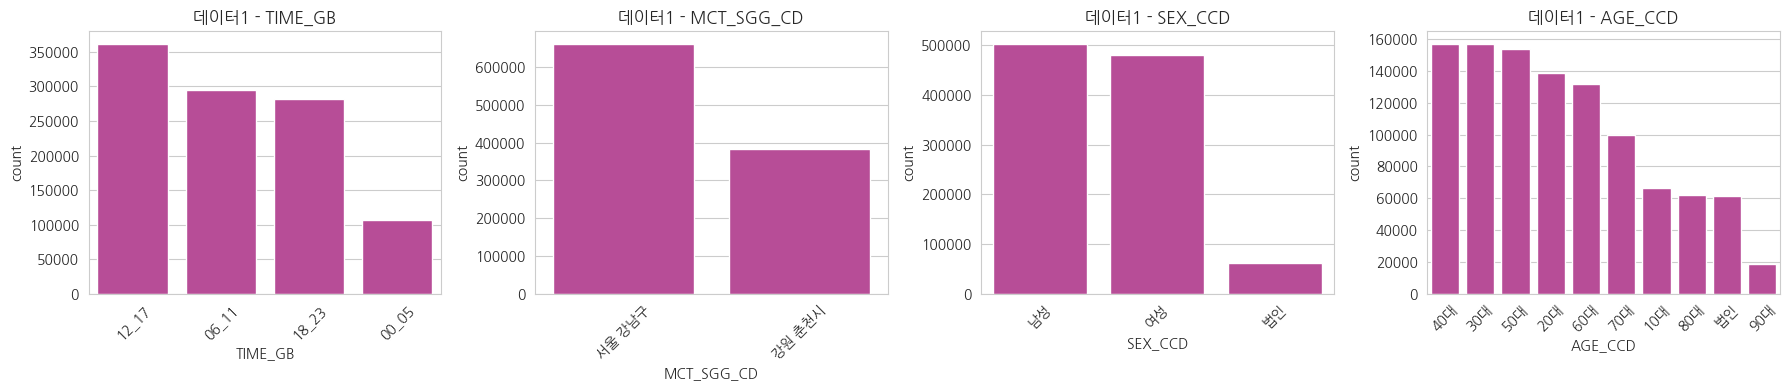

업종 수 - 데이터1: 91 | 데이터2: 90
업종 차이: {'통신요금(PC통신,무선호출)'}
고객 거주지(CLN_SGG_CD): 17 개


In [6]:
# %% 4. 범주형 변수 분포 (행 수 기준)
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

cat1 = ['TIME_GB', 'MCT_SGG_CD', 'SEX_CCD', 'AGE_CCD']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, cat1):
    sns.countplot(data=df1, x=c, ax=ax, order=df1[c].value_counts().index, color="#C83C9E")
    ax.set_title(f'데이터1 - {c}'); ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.savefig(OUT + '01_cat_dist.png', dpi=120); plt.show()

print('업종 수 - 데이터1:', df1['MCT_RY_CD'].nunique(), '| 데이터2:', df2['MCT_RY_CD'].nunique())
print('업종 차이:', set(df1['MCT_RY_CD']) ^ set(df2['MCT_RY_CD']))
print('고객 거주지(CLN_SGG_CD):', df2['CLN_SGG_CD'].nunique(), '개')

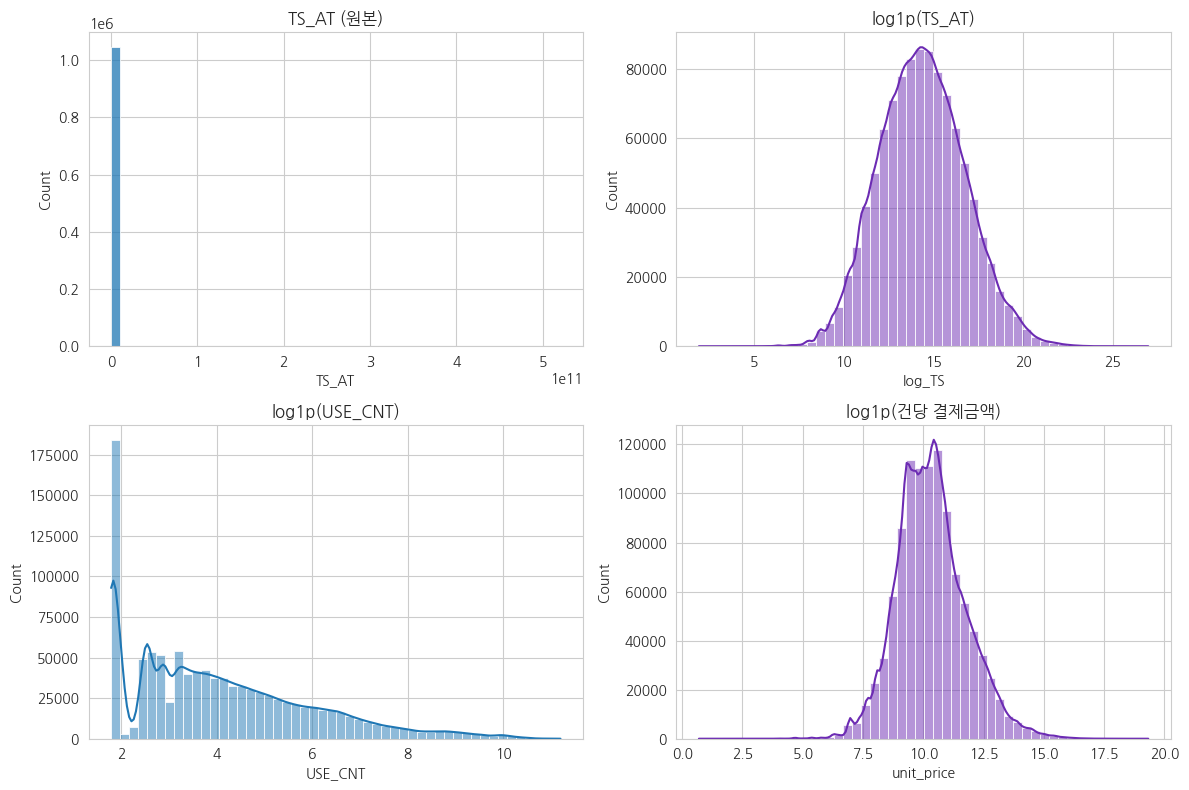

왜도 원본: 429.9668504497624 | 로그: 0.14578990625289143


In [7]:
# %% 5. 수치형 분포 (왜도 확인 -> 로그 변환)
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df1['TS_AT'], bins=50, ax=axes[0, 0]);          axes[0, 0].set_title('TS_AT (원본)')
sns.histplot(df1['log_TS'], color="#6C2BB3", bins=50, kde=True, ax=axes[0, 1]); axes[0, 1].set_title('log1p(TS_AT)')
sns.histplot(np.log1p(df1['USE_CNT']), bins=50, kde=True, ax=axes[1, 0]); axes[1, 0].set_title('log1p(USE_CNT)')
sns.histplot(np.log1p(df1['unit_price']), color="#6C2BB3", bins=50, kde=True, ax=axes[1, 1]); axes[1, 1].set_title('log1p(건당 결제금액)')
plt.tight_layout(); plt.savefig(OUT + '02_num_dist.png', dpi=120); plt.show()
print('왜도 원본:', df1['TS_AT'].skew(), '| 로그:', df1['log_TS'].skew())

          TA_YMD  SGG MCT_RY_CD SEX_CCD         TS_AT  USE_CNT
266988  20250806  강남구    ZZ_나머지      법인  520512895491    16270
475447  20250904  강남구    ZZ_나머지      법인  299091722044    19579
840662  20251229  강남구     세금공과금      남성  289646721166     7773
671046  20251010  강남구    ZZ_나머지      법인  173658599830    13753
95643   20250704  강남구    ZZ_나머지      법인  160960081300    16069
           TA_YMD  SGG MCT_RY_CD SEX_CCD        TS_AT  USE_CNT
953360   20251201  강남구     세금공과금      법인  64874808897      261
541960   20251027  강남구     세금공과금      법인  57981146108      247
1040699  20251210  강남구     세금공과금      법인  31354114431      235
863114   20251124  강남구      기타의료      남성    539352695        5
776779   20251027  강남구      기타의료      남성   1039249933       11


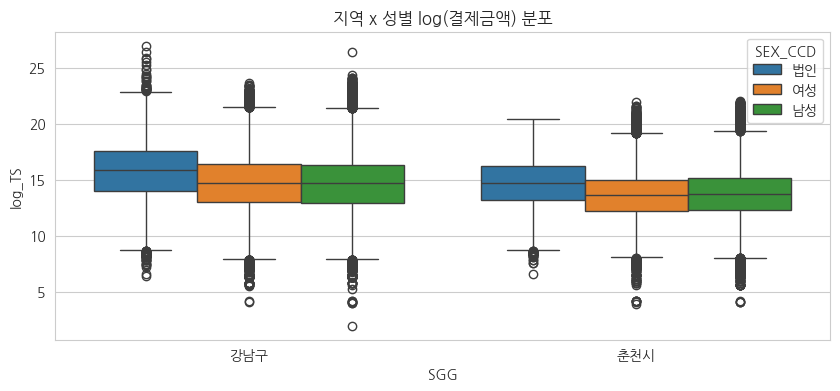

In [15]:
# %% 6. 이상치 확인 (상위 결제액 / 건당금액)
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False
print(df1.nlargest(5, 'TS_AT')[['TA_YMD', 'SGG', 'MCT_RY_CD', 'SEX_CCD', 'TS_AT', 'USE_CNT']])
print(df1.nlargest(5, 'unit_price')[['TA_YMD', 'SGG', 'MCT_RY_CD', 'SEX_CCD', 'TS_AT', 'USE_CNT']])
plt.figure(figsize=(10, 4))
sns.boxplot(data=df1, x='SGG', y='log_TS', hue='SEX_CCD')
plt.title('지역 x 성별 log(결제금액) 분포'); plt.savefig(OUT + '03_box.png', dpi=120); plt.show()

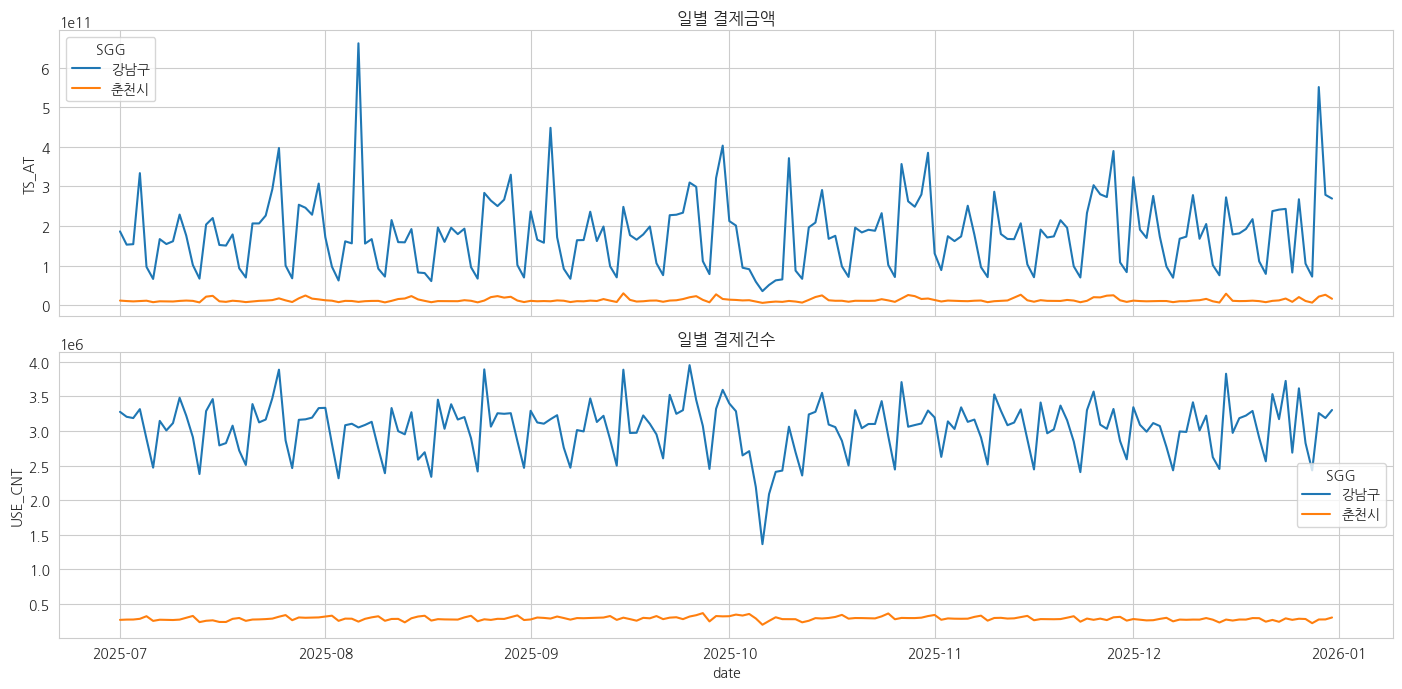

일별 결제금액 최저일:
           date  SGG        TS_AT  USE_CNT
194 2025-10-06  강남구  35651689412  1365497
195 2025-10-06  춘천시   6028559737   200642


In [16]:
# %% 7. 일별 추이 (강남 vs 춘천)
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False
daily = df1.groupby(['date', 'SGG'])[['TS_AT', 'USE_CNT']].sum().reset_index()
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
sns.lineplot(data=daily, x='date', y='TS_AT', hue='SGG', ax=axes[0]);  axes[0].set_title('일별 결제금액')
sns.lineplot(data=daily, x='date', y='USE_CNT', hue='SGG', ax=axes[1]); axes[1].set_title('일별 결제건수')
plt.tight_layout(); plt.savefig(OUT + '04_daily.png', dpi=120); plt.show()
print('일별 결제금액 최저일:\n', daily.loc[daily.groupby('SGG')['TS_AT'].idxmin()])

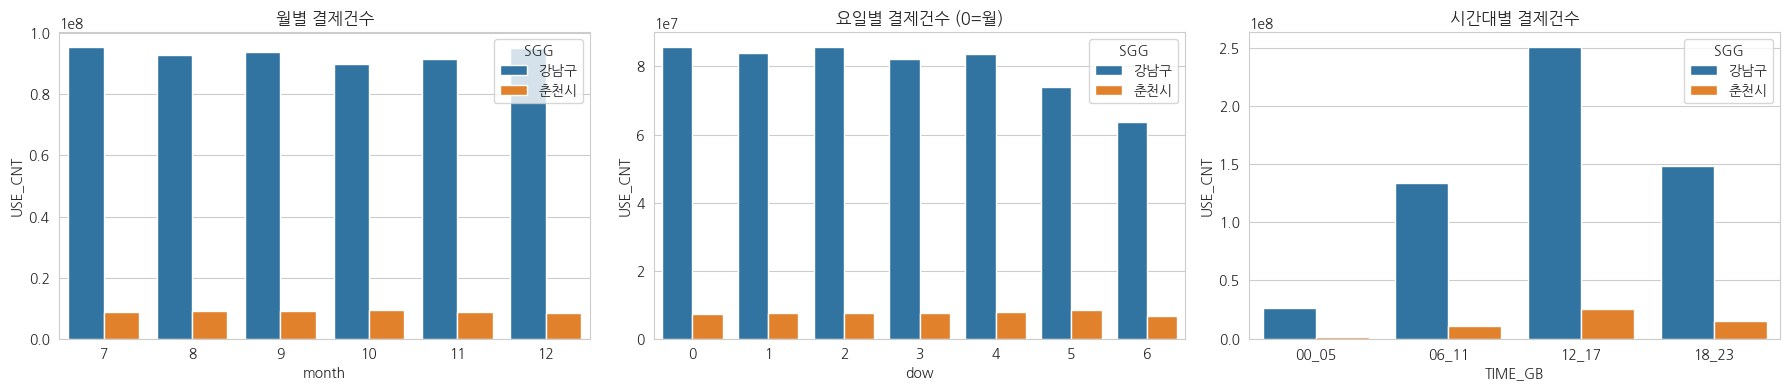

In [17]:
# %% 8. 월별 / 요일별 / 시간대별 패턴
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.barplot(data=df1.groupby(['month', 'SGG'])['USE_CNT'].sum().reset_index(), x='month', y='USE_CNT', hue='SGG', ax=axes[0])
axes[0].set_title('월별 결제건수')
sns.barplot(data=df1.groupby(['dow', 'SGG'])['USE_CNT'].sum().reset_index(), x='dow', y='USE_CNT', hue='SGG', ax=axes[1])
axes[1].set_title('요일별 결제건수 (0=월)')
sns.barplot(data=df1.groupby(['TIME_GB', 'SGG'])['USE_CNT'].sum().reset_index(), x='TIME_GB', y='USE_CNT', hue='SGG', ax=axes[2])
axes[2].set_title('시간대별 결제건수')
plt.tight_layout(); plt.savefig(OUT + '05_time_pattern.png', dpi=120); plt.show()

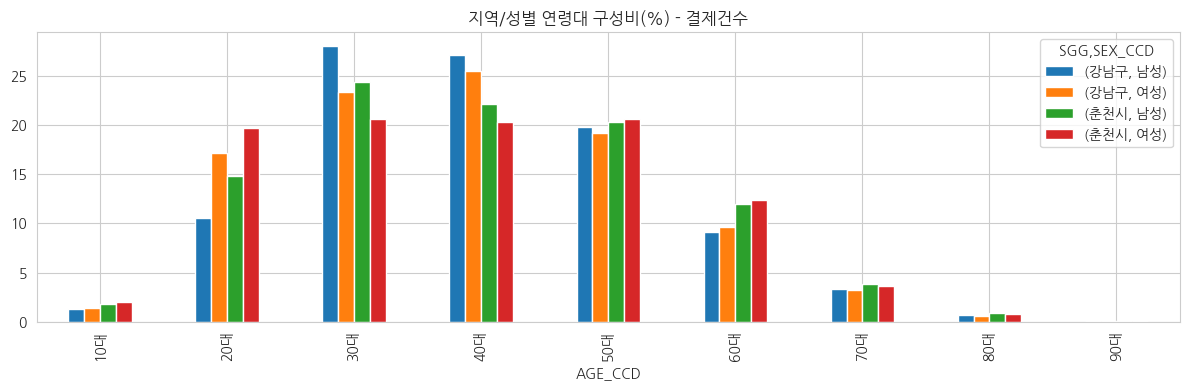

/var/folders/jk/7911w6gd49l0yywr1xjv_8x00000gn/T/ipykernel_90688/2411471806.py:11: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print('법인 매출 비중(%):\n', df1.groupby('SGG').apply(lambda x: x.loc[x.SEX_CCD == '법인', 'TS_AT'].sum() / x['TS_AT'].sum() * 100))


법인 매출 비중(%):
 SGG
강남구   16.13
춘천시   13.10
dtype: float64


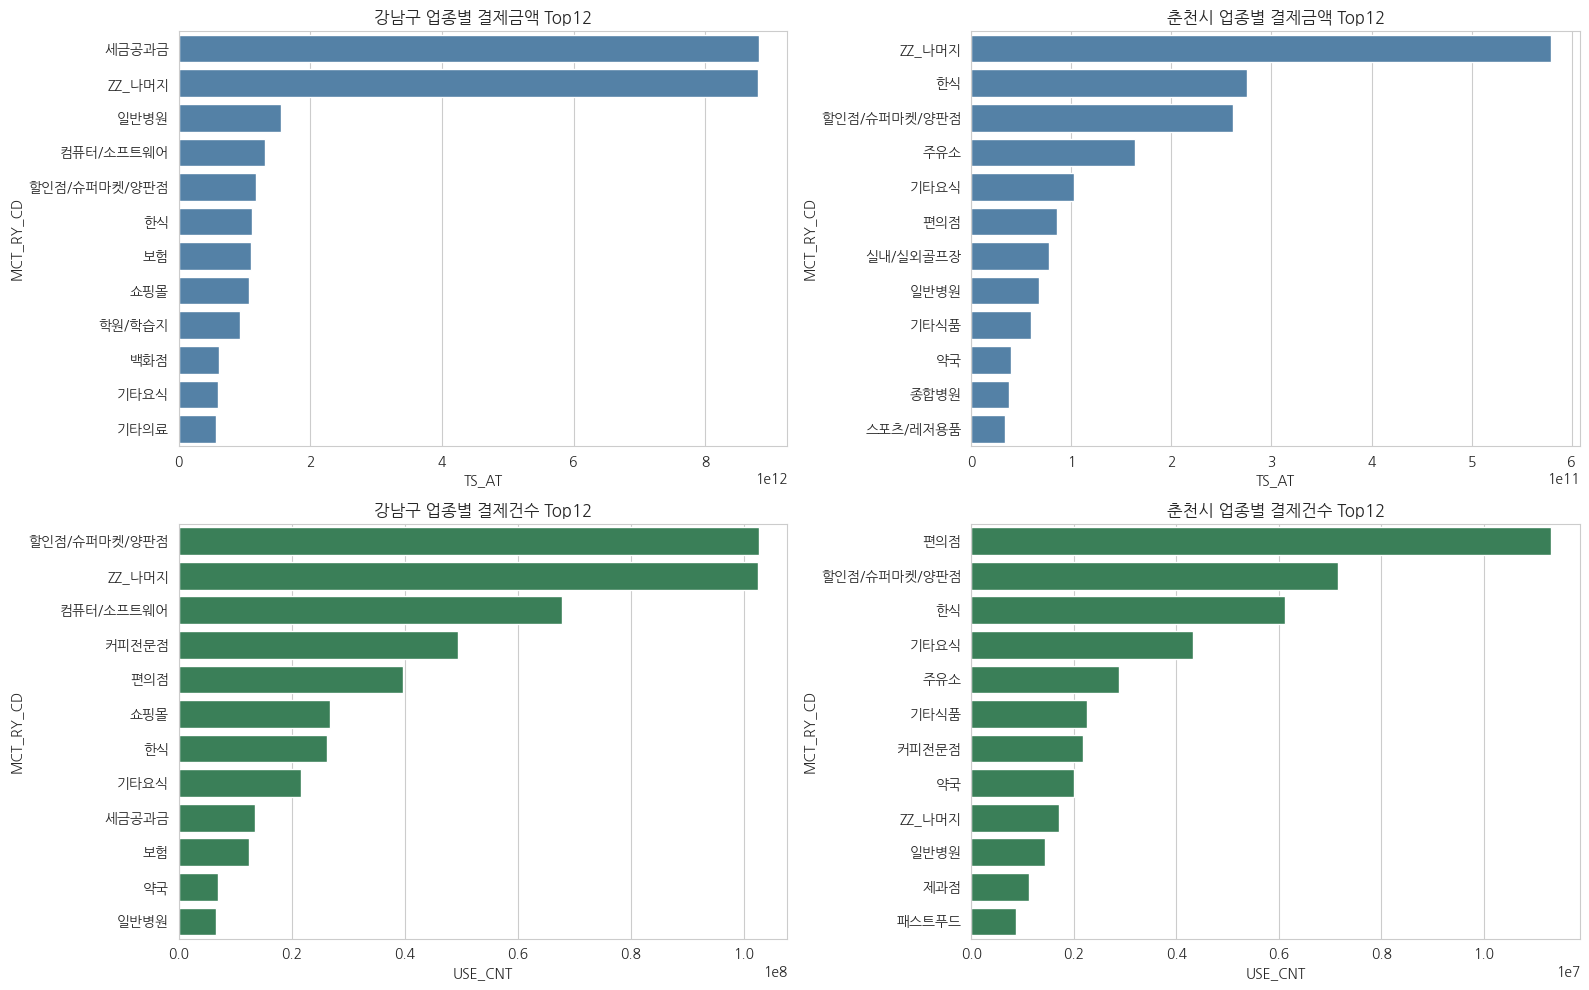

ZZ_나머지 + 세금공과금 매출 비중(%): 50.69476277010499
SGG          강남구   춘천시
CLN_SGG_CD            
강원          2.00 82.10
경기         27.30  7.60
서울         39.90  6.40
인천          5.60  1.20
충북          2.40  0.50
충남          2.30  0.30
경북          2.30  0.30
대전          1.80  0.20
부산          3.60  0.20
경남          3.00  0.20
전남광주        3.10  0.20
대구          2.50  0.20
전북          1.50  0.20
세종          0.60  0.10
제주          0.70  0.10
울산          1.30  0.10
정보없음        0.10  0.10


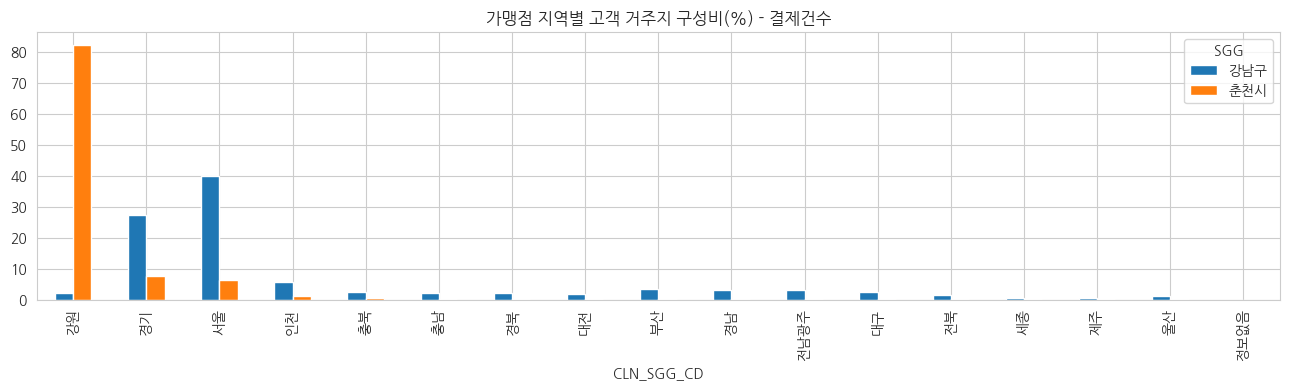

데이터1(법인제외):
               TS_AT    USE_CNT
SGG                           
강남구  28089942680881  521025143
춘천시   2061142150034   50935331 
데이터2:
               TS_AT    USE_CNT
SGG                           
강남구  28089942678769  520928789
춘천시   2061142149283   50905195 
차이(%):
      TS_AT  USE_CNT
SGG                
강남구   0.00     0.02
춘천시   0.00     0.06
            TS_AT  USE_CNT  unit_price
TS_AT        1.00     0.79        0.55
USE_CNT      0.79     1.00       -0.02
unit_price   0.55    -0.02        1.00


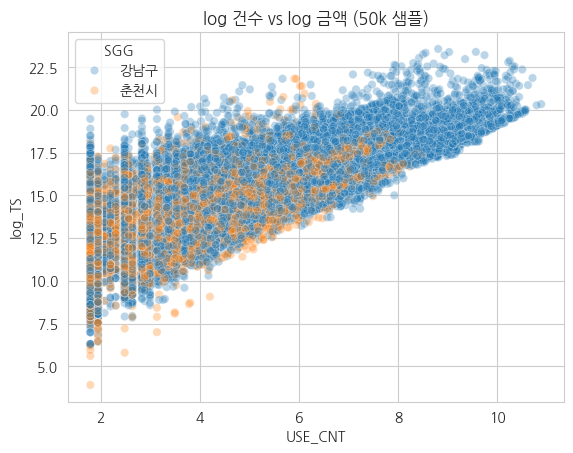

['LPG가스', 'ZZ_나머지', '가구', '가전', '게임방/오락실', '결제대행(PG)', '고속버스/철도/여객선', '기타식품', '기타요식', '기타유통', '기타의료', '노래방', '농수산물', '독서실', '동물병원', '면세점', '모텔,여관,기타숙박', '문화용품', '미용서비스', '미용실', '방문판매/다단계판매', '백화점', '법률/사무서비스', '보건소', '보험', '부동산중개', '사무기기/문구용품', '상품권/복권', '생활잡화/수입상품점', '서점', '세금공과금', '세탁소', '쇼핑몰', '수입자동차', '수제용품점', '스포츠/레저용품', '스포츠시설', '시계/귀금속', '실내/실외골프장', '싸우나/목욕탕', '악기/음반', '안마/마사지', '애완동물', '약국', '양식', '여행사/항공사', '연구/번역서비스', '영화/공연', '예식장/결혼서비스', '오토바이', '완구/아동용자전거', '유치원', '유흥업소', '의복/의류', '인테리어/건축자재/주방기구', '일반병원', '일식', '자동차서비스', '자동차용품', '장례식장/묘지/장의사', '전용매장', '정육점', '제과점', '종합레저타운/놀이동산', '종합병원', '주류판매', '주유소', '주차장', '중고차판매', '중고품판매점', '중식', '체인점', '치과병원', '커피전문점', '컴퓨터/소프트웨어', '택시', '통신요금(PC통신,무선호출)', '통신요금(이동,시내전화)', '패션잡화', '패스트푸드', '편의점', '학교등록금', '학원/학습지', '한식', '한의원', '할인점/슈퍼마켓/양판점', '헬스장', '호텔/콘도', '화원', '화장품', '회계/변리서비스']


In [18]:

plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

# %% 9. 성별 x 연령대 (건수 기준 비중, 지역별)
age_order = ['10대', '20대', '30대', '40대', '50대', '60대', '70대', '80대', '90대']
tmp = df1[df1['SEX_CCD'] != '법인']
pv = tmp.pivot_table(index='AGE_CCD', columns=['SGG', 'SEX_CCD'], values='USE_CNT', aggfunc='sum').reindex(age_order)
pv = pv / pv.sum() * 100
pv.plot(kind='bar', figsize=(12, 4), title='지역/성별 연령대 구성비(%) - 결제건수')
plt.tight_layout(); plt.savefig(OUT + '06_age_sex.png', dpi=120); plt.show()
print('법인 매출 비중(%):\n', df1.groupby('SGG').apply(lambda x: x.loc[x.SEX_CCD == '법인', 'TS_AT'].sum() / x['TS_AT'].sum() * 100))

# %% 10. 업종 분석 (매출 상위 / 건수 상위, 지역별)
top_sales = df1.groupby(['SGG', 'MCT_RY_CD'])['TS_AT'].sum().reset_index()
top_cnt = df1.groupby(['SGG', 'MCT_RY_CD'])['USE_CNT'].sum().reset_index()
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for i, sgg in enumerate(['강남구', '춘천시']):
    sns.barplot(data=top_sales[top_sales.SGG == sgg].nlargest(12, 'TS_AT'), y='MCT_RY_CD', x='TS_AT', ax=axes[0, i], color='steelblue')
    axes[0, i].set_title(f'{sgg} 업종별 결제금액 Top12')
    sns.barplot(data=top_cnt[top_cnt.SGG == sgg].nlargest(12, 'USE_CNT'), y='MCT_RY_CD', x='USE_CNT', ax=axes[1, i], color='seagreen')
    axes[1, i].set_title(f'{sgg} 업종별 결제건수 Top12')
plt.tight_layout(); plt.savefig(OUT + '07_industry.png', dpi=120); plt.show()
print('ZZ_나머지 + 세금공과금 매출 비중(%):',
      df1[df1.MCT_RY_CD.isin(['ZZ_나머지', '세금공과금'])]['TS_AT'].sum() / df1['TS_AT'].sum() * 100)

# %% 11. 데이터2: 고객 거주지 (외부 유입 구조)
flow = df2.pivot_table(index='CLN_SGG_CD', columns='SGG', values='USE_CNT', aggfunc='sum')
flow_pct = (flow / flow.sum() * 100).sort_values('춘천시', ascending=False)
print(flow_pct.round(1))
flow_pct.plot(kind='bar', figsize=(13, 4), title='가맹점 지역별 고객 거주지 구성비(%) - 결제건수')
plt.tight_layout(); plt.savefig(OUT + '08_resident.png', dpi=120); plt.show()

# %% 12. 데이터1 vs 데이터2 정합성 (법인 제외 시 일치하는지)
chk1 = df1[df1.SEX_CCD != '법인'].groupby('SGG')[['TS_AT', 'USE_CNT']].sum()
chk2 = df2.groupby('SGG')[['TS_AT', 'USE_CNT']].sum()
print('데이터1(법인제외):\n', chk1, '\n데이터2:\n', chk2, '\n차이(%):\n', ((chk1 - chk2) / chk1 * 100).round(4))

# %% 13. 상관관계 / 지역x업종 건당금액
print(df1[['TS_AT', 'USE_CNT', 'unit_price']].corr(method='spearman'))
samp = df1.sample(50000, random_state=42)
sns.scatterplot(data=samp, x=np.log1p(samp['USE_CNT']), y='log_TS', hue='SGG', alpha=.3)
plt.title('log 건수 vs log 금액 (50k 샘플)'); plt.savefig(OUT + '09_scatter.png', dpi=120); plt.show()

# =====================================================================
# 부록: 기후 취약 상권 분석용 분할 예시 (필요한 셀만 사용)
# =====================================================================
# %% A. 분석 단위 분할
gn1, cc1 = df1[df1.SGG == '강남구'].copy(), df1[df1.SGG == '춘천시'].copy()     # 지역별
df1_ind = df1[df1.SEX_CCD != '법인'].copy()                                     # 개인 고객만
df1_core = df1[~df1.MCT_RY_CD.isin(['ZZ_나머지', '세금공과금'])].copy()          # 노이즈 업종 제외

# %% B. 업종 그룹핑 (날씨 민감도 가설 기반) - 업종명은 df1.MCT_RY_CD.unique()로 확인 후 수정
print(sorted(df1['MCT_RY_CD'].unique()))
# weather_map = {'야외': [...], '실내': [...], '배달/근거리': [...], '필수소비': [...]}
# df1['ry_group'] = df1['MCT_RY_CD'].map({v: k for k, vs in weather_map.items() for v in vs})

# %% C. 기상 데이터 결합 (일 단위 key = date x SGG)
# weather = pd.read_csv('기상청_일별.csv')  # 강남(서울 108/422?) / 춘천 관측소, 일 강수량·최고기온·폭염/한파/태풍 여부
# m = daily.merge(weather, on=['date', 'SGG'], how='left')
# 기후 이벤트 전후 비교: 평년 같은 요일 대비 결제건수 증감률 = (event일 건수 / 동일 요일 평균) - 1

---

## SK텔레콤 EDA

In [3]:
# =====================================================================
# SK텔레콤 유동인구 데이터 EDA + 신한카드 병합 코드
# 파일 3종 x 6개월(2025.07~12)
#   flow_wkdy_pop_YYYYMM : 격자(50m)별 '요일별' 평균 유동인구 (월~일)
#   flow_time_pop_YYYYMM : 격자별 '시간대별'(00~23시) 유동인구
#   flow_age_pop_YYYYMM  : 격자별 '성별 x 연령대' 유동인구
# 구분자 '|' , 인코딩 utf-8-sig.  BLOCK_CD 앞 5자리 = 시군구 (11230 강남구, 32010 춘천시)
# 실행: PATH만 수정 후 # %% 셀 순서대로 실행
# =====================================================================

# %% 0. 환경설정
import glob, os, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['font.family'] = {'Windows': 'Malgun Gothic', 'Darwin': 'AppleGothic'}.get(platform.system(), 'NanumGothic')
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.options.display.float_format = '{:,.2f}'.format

PATH = '../data/sk_flow_pop_data/'               # <- SKT 파일 폴더
SK_PATH = '../data/SH_card_data/'      # <- 신한카드 파일 폴더 (병합 파트에서 사용)
OUT = './figs_skt/'
os.makedirs(OUT, exist_ok=True)

# %% 1. 로드 (월별 18개 파일 -> 3개 DataFrame)
rd = dict(sep='|', encoding='utf-8-sig', dtype={'BLOCK_CD': str, 'STD_YM': str})
wk = pd.concat([pd.read_csv(f, **rd) for f in sorted(glob.glob(PATH + 'flow_wkdy_pop_*.csv'))], ignore_index=True)
tm = pd.concat([pd.read_csv(f, **rd) for f in sorted(glob.glob(PATH + 'flow_time_pop_*.csv'))], ignore_index=True)
ag = pd.concat([pd.read_csv(f, **rd) for f in sorted(glob.glob(PATH + 'flow_age_pop_*.csv'))], ignore_index=True)

# %% 2. 기본 구조 / 품질 점검
for name, df in [('요일별', wk), ('시간대별', tm), ('연령별', ag)]:
    print(f'===== {name} =====')
    print('shape:', df.shape, '| 결측:', df.isna().sum().sum(), '| 월:', sorted(df.STD_YM.unique()))
    print('완전중복행:', df.duplicated().sum(), '| 월별 중복:', df[df.duplicated()].STD_YM.value_counts().to_dict())
    print('BLOCK_CD 자리수:', df.BLOCK_CD.str.len().unique(), '| 집계구 수:', df.BLOCK_CD.nunique())
print(wk.head(3))


===== 요일별 =====
shape: (842073, 11) | 결측: 0 | 월: ['202507', '202508', '202509', '202510', '202511', '202512']
완전중복행: 121267 | 월별 중복: {'202512': 121267}
BLOCK_CD 자리수: [20] | 집계구 수: 2799
===== 시간대별 =====
shape: (663350, 28) | 결측: 0 | 월: ['202507', '202508', '202509', '202510', '202511', '202512']
완전중복행: 92545 | 월별 중복: {'202512': 92545}
BLOCK_CD 자리수: [20] | 집계구 수: 2793
===== 연령별 =====
shape: (596252, 16) | 결측: 0 | 월: ['202507', '202508', '202509', '202510', '202511', '202512']
완전중복행: 0 | 월별 중복: {}
BLOCK_CD 자리수: [20] | 집계구 수: 2794
   STD_YM              BLOCK_CD      X_COORD      Y_COORD  FLOW_POP_CNT_MON  FLOW_POP_CNT_TUS  FLOW_POP_CNT_WED  FLOW_POP_CNT_THU  FLOW_POP_CNT_FRI  FLOW_POP_CNT_SAT  FLOW_POP_CNT_SUN
0  202507  32010350100010000001 1,000,583.99 1,969,379.15              1.60              1.55              2.03              1.98              2.39              0.00              0.00
1  202507  32010350100010000001 1,000,583.99 1,969,429.15              2.03              2.03      

In [4]:
# %% 3. 12월 중복 제거 (요일별·시간대별 12월 파일은 모든 행이 2번씩 들어 있음)
n0 = len(wk), len(tm)
wk = wk.drop_duplicates().reset_index(drop=True)
tm = tm.drop_duplicates().reset_index(drop=True)
print('제거 전:', n0, '-> 제거 후:', len(wk), len(tm))
for df in (wk, tm, ag):
    print('키(월,집계구,X,Y) 중복:', df.duplicated(['STD_YM', 'BLOCK_CD', 'X_COORD', 'Y_COORD']).sum())

제거 전: (842073, 663350) -> 제거 후: 720806 570805
키(월,집계구,X,Y) 중복: 0
키(월,집계구,X,Y) 중복: 0
키(월,집계구,X,Y) 중복: 0


In [6]:
print('#####요일별#####')
display(wk.head())
print('#####시간별#####')
display(tm.head())
print('#####연령별#####')
display(ag.head())

#####요일별#####


,STD_YM,BLOCK_CD,X_COORD,Y_COORD,FLOW_POP_CNT_MON,FLOW_POP_CNT_TUS,FLOW_POP_CNT_WED,FLOW_POP_CNT_THU,FLOW_POP_CNT_FRI,FLOW_POP_CNT_SAT,FLOW_POP_CNT_SUN
0,202507,32010350100010000001,"1,000,583.99","1,969,379.15",1.60,1.55,2.03,1.98,2.39,0.00,0.00
1,202507,32010350100010000001,"1,000,583.99","1,969,429.15",2.03,2.03,1.98,2.06,1.98,0.00,0.00
2,202507,32010350100010000001,"1,000,583.99","1,969,529.15",1.78,1.70,2.06,2.01,2.31,0.00,0.00
3,202507,32010350100010000001,"1,000,583.99","1,969,579.15",0.33,0.38,0.30,0.30,0.30,0.00,0.00
4,202507,32010350100010000001,"1,000,583.99","1,969,629.15",1.91,1.91,1.85,1.91,1.85,0.00,0.00


#####시간별#####


,STD_YM,BLOCK_CD,X_COORD,Y_COORD,TMST_00,TMST_01,TMST_02,TMST_03,TMST_04,TMST_05,TMST_06,TMST_07,TMST_08,TMST_09,TMST_10,TMST_11,TMST_12,TMST_13,TMST_14,TMST_15,TMST_16,TMST_17,TMST_18,TMST_19,TMST_20,TMST_21,TMST_22,TMST_23
0,202507,32010350100010000001,"1,000,583.99","1,969,379.15",0.03,0.03,0.03,0.00,0.00,0.03,0.03,0.05,0.08,0.10,0.10,0.10,0.10,0.10,0.10,0.13,0.10,0.08,0.10,0.08,0.05,0.05,0.03,0.03
1,202507,32010350100010000001,"1,000,583.99","1,969,429.15",0.03,0.03,0.03,0.00,0.03,0.03,0.03,0.03,0.05,0.08,0.08,0.13,0.15,0.13,0.13,0.10,0.10,0.10,0.08,0.08,0.05,0.05,0.03,0.03
2,202507,32010350100010000001,"1,000,583.99","1,969,529.15",0.03,0.03,0.03,0.03,0.03,0.03,0.03,0.05,0.08,0.08,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.08,0.08,0.08,0.05,0.05,0.03,0.03
3,202507,32010350100010000001,"1,000,583.99","1,969,579.15",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.03,0.03,0.03,0.03,0.00,0.03,0.03,0.03,0.03,0.00,0.03,0.03,0.00,0.00,0.00,0.00
4,202507,32010350100010000001,"1,000,583.99","1,969,629.15",0.03,0.03,0.00,0.00,0.00,0.03,0.03,0.03,0.05,0.08,0.08,0.13,0.13,0.13,0.13,0.10,0.10,0.08,0.08,0.08,0.05,0.03,0.03,0.03


#####연령별#####


,STD_YM,BLOCK_CD,X_COORD,Y_COORD,MAN_FLOW_POP_CNT_10G,MAN_FLOW_POP_CNT_20G,MAN_FLOW_POP_CNT_30G,MAN_FLOW_POP_CNT_40G,MAN_FLOW_POP_CNT_50G,MAN_FLOW_POP_CNT_60GU,WMAN_FLOW_POP_CNT_10G,WMAN_FLOW_POP_CNT_20G,WMAN_FLOW_POP_CNT_30G,WMAN_FLOW_POP_CNT_40G,WMAN_FLOW_POP_CNT_50G,WMAN_FLOW_POP_CNT_60GU
0,202507,11230510101020000001,"956,633.99","1,947,479.15",0.00,0.05,0.05,0.08,0.10,0.05,0.03,0.08,0.05,0.05,0.05,0.05
1,202507,11230510101020000001,"956,683.99","1,947,429.15",0.00,0.08,0.10,0.15,0.15,0.15,0.00,0.08,0.08,0.08,0.05,0.08
2,202507,11230510101020000001,"956,683.99","1,947,479.15",0.00,0.05,0.05,0.10,0.10,0.08,0.03,0.05,0.05,0.05,0.05,0.08
3,202507,11230510101020000001,"956,683.99","1,947,579.15",0.03,0.08,0.15,0.15,0.18,0.15,0.00,0.08,0.10,0.10,0.10,0.08
4,202507,11230510101020000001,"956,733.99","1,947,379.15",0.48,0.69,0.97,1.19,1.22,1.27,0.46,0.71,0.81,0.89,0.79,0.86


In [9]:
wk.BLOCK_CD.str[:5].unique()

array(['32010', '31370', '32310', '32370', '32380', '11230', '11030',
       '11220', '11040', '11240'], dtype=object)

SGG
춘천시        627415
강남구         92750
기타(인접지)       641
Name: count, dtype: int64 
 SGG
춘천시        478348
강남구         92127
기타(인접지)       330
Name: count, dtype: int64 
 SGG
춘천시        503807
강남구         92108
기타(인접지)       337
Name: count, dtype: int64
                      count  mean    std  min  50%      99%    99.9%       max
FLOW_POP_CNT_MON 720,806.00 79.98 401.61 0.00 0.97 1,866.60 5,289.79 14,515.97
FLOW_POP_CNT_TUS 720,806.00 82.69 417.09 0.00 0.94 1,942.69 5,493.40 14,720.37
FLOW_POP_CNT_WED 720,806.00 82.82 416.86 0.00 0.94 1,940.96 5,484.69 14,539.90
FLOW_POP_CNT_THU 720,806.00 82.40 414.67 0.00 0.97 1,929.43 5,419.14 14,640.81
FLOW_POP_CNT_FRI 720,806.00 83.06 416.02 0.00 1.04 1,941.63 5,454.11 14,987.07
FLOW_POP_CNT_SAT 720,806.00 69.09 322.08 0.00 0.81 1,469.38 4,304.78 10,997.03
FLOW_POP_CNT_SUN 720,806.00 57.87 260.17 0.00 0.76 1,196.08 3,434.02  7,913.45
0값 비율:
 FLOW_POP_CNT_MON   0.03
FLOW_POP_CNT_TUS   0.03
FLOW_POP_CNT_WED   0.03
FLOW_POP_CNT_THU   0.03
FLOW_POP

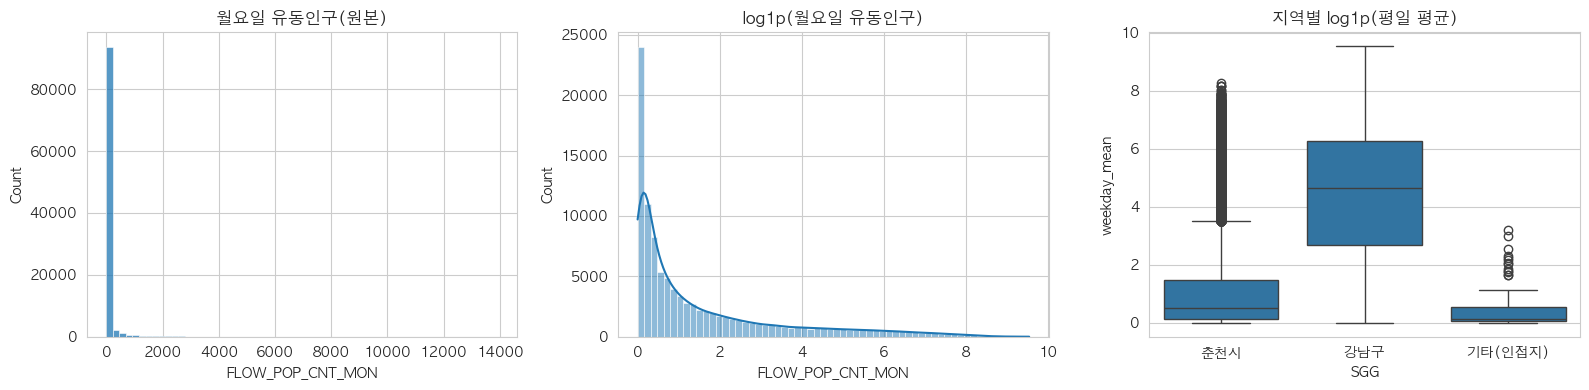

왜도 원본: 10.544033710160956 | 로그: 1.6150230801977312
                 요일별합/7        시간대별합         연령별합  시간-연령 차이(%)
STD_YM SGG                                                    
202507 강남구 7,476,071.23 7,543,179.73 7,542,992.26         0.00
       춘천시 1,799,295.59 1,799,434.69 1,796,427.22         0.17
202508 강남구 7,280,376.53 7,184,533.73 7,184,339.15         0.00
       춘천시 1,864,529.20 1,863,773.85 1,860,687.43         0.17
202509 강남구 7,565,907.16 7,599,627.85 7,599,422.51         0.00
       춘천시 1,955,331.58 1,957,719.52 1,954,764.60         0.15
202510 강남구 7,057,797.10 7,132,667.55 7,132,356.84         0.00
       춘천시 1,889,318.64 1,892,477.97 1,889,352.36         0.17
202511 강남구 7,562,020.27 7,459,365.08 7,459,149.71         0.00
       춘천시 1,869,409.66 1,864,186.96 1,861,328.88         0.15
202512 강남구 7,259,708.04 7,320,846.87 7,320,643.58         0.00
       춘천시 1,773,592.29 1,777,045.08 1,774,360.64         0.15
7월 격자 수: {'wk': 117825, 'tm': 94099, 'ag': 98129}
시간대 ⊂ 요일별: True |

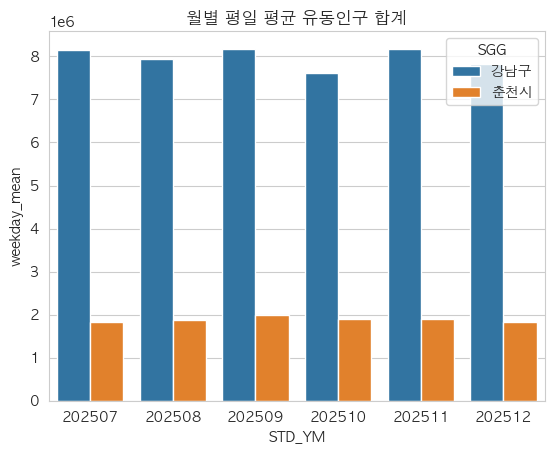

        월      화      수      목      금     토     일
SGG                                              
강남구 97.00 100.90 101.00 100.40 100.80 80.40 65.70
춘천시 98.90  99.50  99.80  99.60 102.20 99.50 90.20


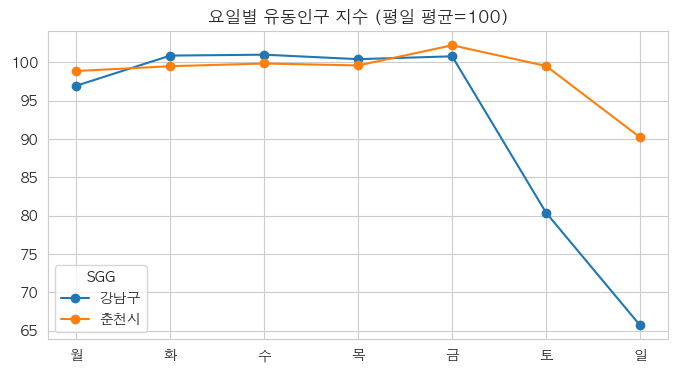

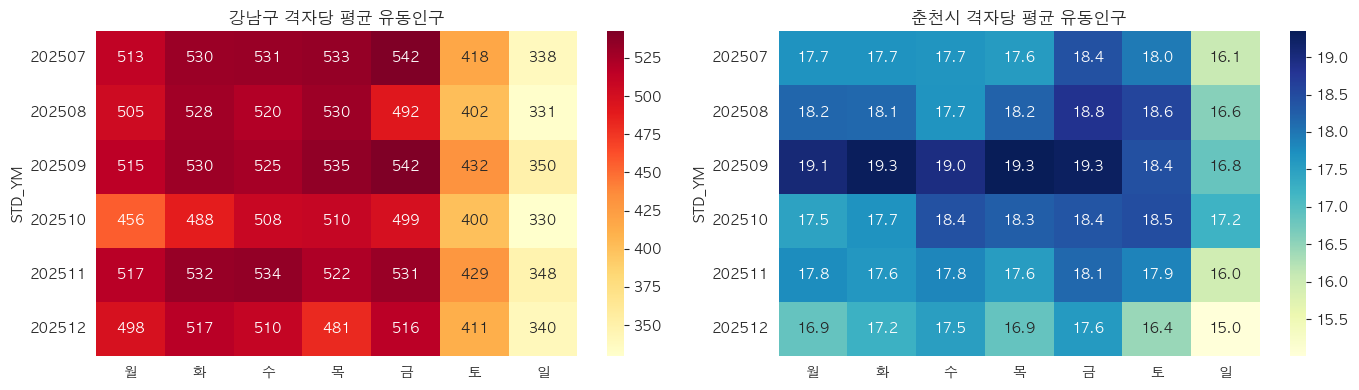

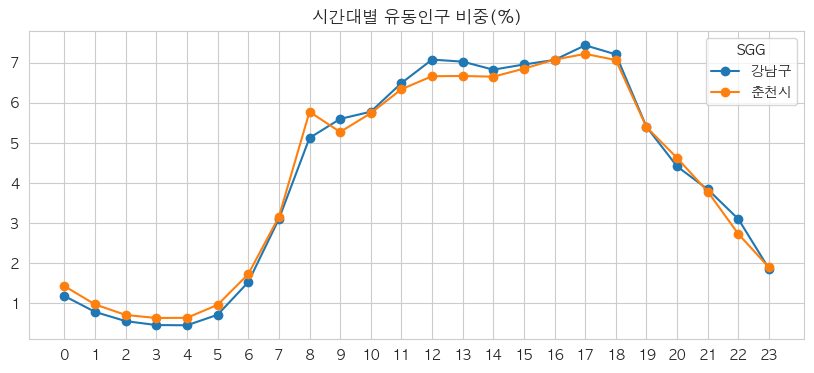

         tb_00_05  tb_06_11  tb_12_17  tb_18_23
SGG                                            
강남구          4.20     27.60     42.40     25.80
기타(인접지)      4.50     24.10     42.00     29.30
춘천시          5.30     28.00     41.10     25.50


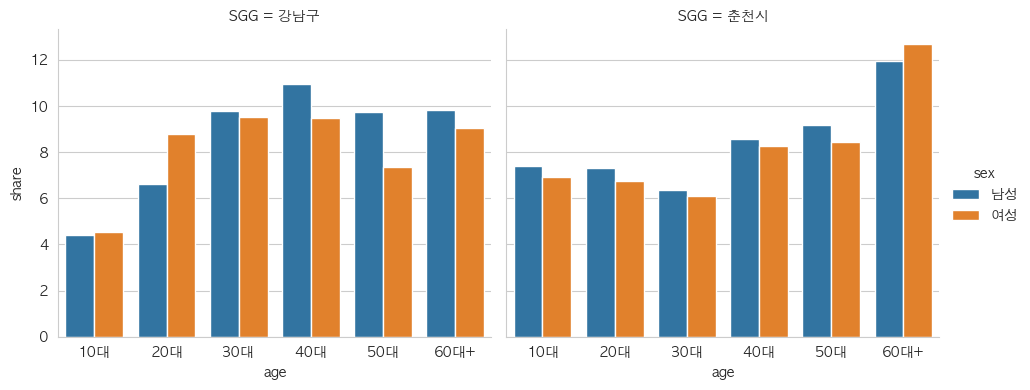

SGG    강남구        춘천시      
sex     남성   여성    남성    여성
age                        
10대   4.40 4.50  7.40  6.90
20대   6.60 8.80  7.30  6.80
30대   9.80 9.50  6.40  6.10
40대  11.00 9.50  8.60  8.30
50대   9.70 7.30  9.20  8.40
60대+  9.80 9.00 12.00 12.70


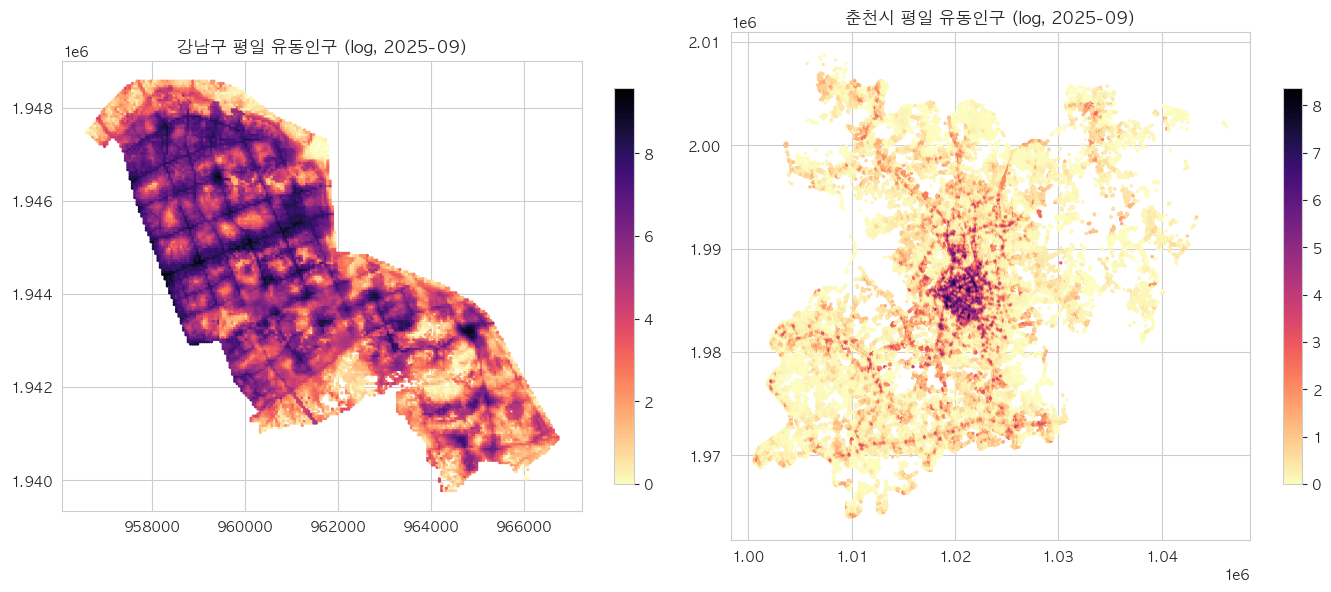

      SGG              BLOCK_CD  weekday_mean
906   강남구  11230640500030000001      8,452.30
832   강남구  11230640300060000002      7,969.38
234   강남구  11230530100030000003      7,699.20
801   강남구  11230640300020000002      7,614.46
849   강남구  11230640300070000008      7,506.50
710   강남구  11230640100010000004      6,586.63
907   강남구  11230640500030000002      6,524.33
1418  강남구  11230750100010000001      6,281.55
955   강남구  11230650100010000009      6,205.30
870   강남구  11230640400030000007      6,084.98
강남구: 상위 1% 격자가 전체 유동인구의 12.9%, 상위 10%가 57.7%
춘천시: 상위 1% 격자가 전체 유동인구의 47.2%, 상위 10%가 90.5%


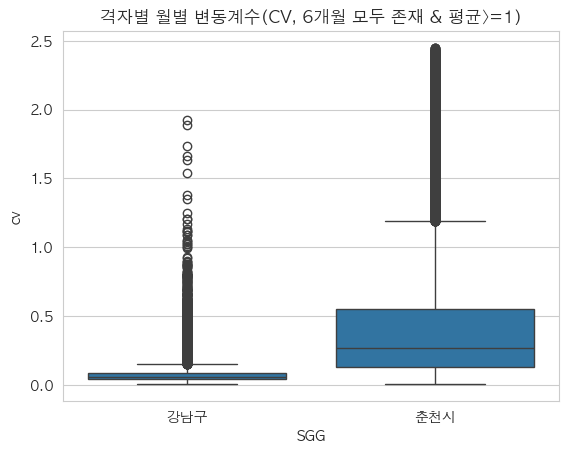

        count  mean  std  min  25%  50%  75%  max
SGG                                              
강남구 14,718.00  0.09 0.11 0.01 0.04 0.06 0.09 1.92
춘천시 46,240.00  0.42 0.44 0.01 0.13 0.27 0.55 2.45


"\n# =====================================================================\n# 병합 파트\n#  (1) SKT 3개 파일 -> 격자x월 단일 마스터 (격자 분석용)\n#  (2) SKT x 신한카드 -> 시군구x월 x {요일 | 시간대 | 성별연령} (소비 전환율 분석용)\n#  * 신한카드에는 좌표가 없어 격자 단위 병합은 불가, 시군구 단위로만 가능\n# =====================================================================\n\n# %% M1. SKT 3개 파일 병합 (격자 마스터)\nbase = wk[['STD_YM', 'BLOCK_CD', 'X_COORD', 'Y_COORD', 'SGG_CD', 'SGG'] + wcols + ['weekday_mean', 'weekend_mean']]\nmtm = tm[['STD_YM', 'BLOCK_CD', 'X_COORD', 'Y_COORD'] + tcols + ['tb_' + k for k in bins]]\nmag = ag[['STD_YM', 'BLOCK_CD', 'X_COORD', 'Y_COORD'] + acols]\nmk = ['STD_YM', 'BLOCK_CD', 'X_COORD', 'Y_COORD']\nmaster = base.merge(mtm, on=mk, how='left').merge(mag, on=mk, how='left')   # 요일별(가장 격자 많음) 기준 left join\nmaster['has_time'] = master['TMST_00'].notna()\nmaster['has_age'] = master['MAN_FLOW_POP_CNT_10G'].notna()\nprint('master:', master.shape, '| 시간대 없음:', (~master.has_time).sum(), '| 연령 없음:', (~master.has_age).sum())\n# 시간·연령 값이 없는

In [7]:
# %% 4. 파생변수 (시군구 코드, 요일/시간/연령 합계)
sgg_name = {'11230': '강남구', '32010': '춘천시'}
wcols = ['FLOW_POP_CNT_MON', 'FLOW_POP_CNT_TUS', 'FLOW_POP_CNT_WED', 'FLOW_POP_CNT_THU',
         'FLOW_POP_CNT_FRI', 'FLOW_POP_CNT_SAT', 'FLOW_POP_CNT_SUN']      # TUS = 화요일(원본 표기)
tcols = [f'TMST_{h:02d}' for h in range(24)]
acols = [c for c in ag.columns if 'FLOW_POP_CNT' in c]

for df in (wk, tm, ag):
    df['SGG_CD'] = df.BLOCK_CD.str[:5]
    df['SGG'] = df.SGG_CD.map(sgg_name).fillna('기타(인접지)')
wk['wk_sum'] = wk[wcols].sum(axis=1)
wk['weekday_mean'] = wk[wcols[:5]].mean(axis=1)
wk['weekend_mean'] = wk[wcols[5:]].mean(axis=1)
tm['t_sum'] = tm[tcols].sum(axis=1)
ag['a_sum'] = ag[acols].sum(axis=1)
print(wk.SGG.value_counts(), '\n', tm.SGG.value_counts(), '\n', ag.SGG.value_counts())

# %% 5. 수치 분포 (심한 우측 꼬리 -> log 변환)
print(wk[wcols].describe(percentiles=[.5, .99, .999]).T)
print('0값 비율:\n', (wk[wcols] == 0).mean())
print('음수 개수:', (wk[wcols] < 0).sum().sum(), (tm[tcols] < 0).sum().sum(), (ag[acols] < 0).sum().sum())
s = wk.sample(100000, random_state=42)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(s['FLOW_POP_CNT_MON'], bins=60, ax=axes[0]);                 axes[0].set_title('월요일 유동인구(원본)')
sns.histplot(np.log1p(s['FLOW_POP_CNT_MON']), bins=60, kde=True, ax=axes[1]); axes[1].set_title('log1p(월요일 유동인구)')
sns.boxplot(data=s, x='SGG', y=np.log1p(s['weekday_mean']), ax=axes[2]);  axes[2].set_title('지역별 log1p(평일 평균)')
plt.tight_layout(); plt.savefig(OUT + '01_dist.png', dpi=120); plt.show()
print('왜도 원본:', wk['FLOW_POP_CNT_MON'].skew(), '| 로그:', np.log1p(wk['FLOW_POP_CNT_MON']).skew())

# %% 6. 정합성: 세 테이블의 총합이 같은 양을 보는가?
chk = pd.concat([wk.groupby(['STD_YM', 'SGG'])['wk_sum'].sum().div(7).rename('요일별합/7'),
                 tm.groupby(['STD_YM', 'SGG'])['t_sum'].sum().rename('시간대별합'),
                 ag.groupby(['STD_YM', 'SGG'])['a_sum'].sum().rename('연령별합')], axis=1)
chk['시간-연령 차이(%)'] = (chk['시간대별합'] / chk['연령별합'] - 1) * 100
print(chk.loc[(slice(None), ['강남구', '춘천시']), :])

# %% 7. 격자 커버리지 (테이블마다 존재하는 격자가 다름)
key = ['STD_YM', 'BLOCK_CD', 'X_COORD', 'Y_COORD']
ks = {n: set(map(tuple, d.loc[d.STD_YM == '202507', key[1:]].round(0).values.tolist())) for n, d in [('wk', wk), ('tm', tm), ('ag', ag)]}
print('7월 격자 수:', {k: len(v) for k, v in ks.items()})
print('시간대 ⊂ 요일별:', ks['tm'] <= ks['wk'], '| 연령 ⊂ 요일별:', ks['ag'] <= ks['wk'], '| 시간∩연령:', len(ks['tm'] & ks['ag']))
cell_months = wk.groupby(['BLOCK_CD', 'X_COORD', 'Y_COORD']).STD_YM.nunique()
print('격자별 등장 월수 분포:\n', cell_months.value_counts().sort_index())
print('월별 격자 수:', wk.groupby('STD_YM').size().to_dict())

# %% 8. 월별 총 유동인구 추이 (지역별)
monthly = wk[wk.SGG != '기타(인접지)'].groupby(['STD_YM', 'SGG'])['weekday_mean'].sum().reset_index()
sns.barplot(data=monthly, x='STD_YM', y='weekday_mean', hue='SGG')
plt.title('월별 평일 평균 유동인구 합계'); plt.savefig(OUT + '02_monthly.png', dpi=120); plt.show()

# %% 9. 요일 패턴 (지역별, 평일 평균=100 지수)
dow_idx = wk[wk.SGG != '기타(인접지)'].groupby('SGG')[wcols].sum()
dow_idx = dow_idx.div(dow_idx[wcols[:5]].mean(axis=1), axis=0) * 100
dow_idx.columns = ['월', '화', '수', '목', '금', '토', '일']
print(dow_idx.round(1))
dow_idx.T.plot(marker='o', figsize=(8, 4), title='요일별 유동인구 지수 (평일 평균=100)')
plt.savefig(OUT + '03_dow.png', dpi=120); plt.show()

# %% 10. 월 x 요일 히트맵 (공휴일 영향 확인, 예: 10월 월요일)
hm = wk[wk.SGG == '강남구'].groupby('STD_YM')[wcols].mean()
hm.columns = ['월', '화', '수', '목', '금', '토', '일']
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(hm, annot=True, fmt='.0f', cmap='YlOrRd', ax=axes[0]); axes[0].set_title('강남구 격자당 평균 유동인구')
hm2 = wk[wk.SGG == '춘천시'].groupby('STD_YM')[wcols].mean(); hm2.columns = hm.columns
sns.heatmap(hm2, annot=True, fmt='.1f', cmap='YlGnBu', ax=axes[1]); axes[1].set_title('춘천시 격자당 평균 유동인구')
plt.tight_layout(); plt.savefig(OUT + '04_heatmap.png', dpi=120); plt.show()

# %% 11. 시간대 패턴 (지역별 정규화 -> 24시간 합=100%)
hr = tm[tm.SGG != '기타(인접지)'].groupby('SGG')[tcols].sum()
hr = hr.div(hr.sum(axis=1), axis=0) * 100
hr.columns = range(24)
hr.T.plot(marker='o', figsize=(10, 4), title='시간대별 유동인구 비중(%)'); plt.xticks(range(24))
plt.savefig(OUT + '05_hour.png', dpi=120); plt.show()
bins = {'00_05': tcols[0:6], '06_11': tcols[6:12], '12_17': tcols[12:18], '18_23': tcols[18:24]}
for k, v in bins.items():
    tm['tb_' + k] = tm[v].sum(axis=1)
print((tm.groupby('SGG')[['tb_' + k for k in bins]].sum().pipe(lambda x: x.div(x.sum(axis=1), axis=0) * 100)).round(1))

# %% 12. 성별 x 연령대 (지역별 구성비 -> 인구 피라미드)
lg = ag[ag.SGG != '기타(인접지)'].melt(id_vars=['STD_YM', 'BLOCK_CD', 'SGG'], value_vars=acols, var_name='col', value_name='pop')
lg['sex'] = np.where(lg['col'].str.startswith('WMAN'), '여성', '남성')
lg['age'] = lg['col'].str.extract(r'_(\d+)G')[0].astype(int).astype(str) + '대'
lg['age'] = lg['age'].replace({'60대': '60대+'})
pyr = lg.groupby(['SGG', 'sex', 'age'])['pop'].sum().reset_index()
pyr['share'] = pyr['pop'] / pyr.groupby('SGG')['pop'].transform('sum') * 100
sns.catplot(data=pyr, x='age', y='share', hue='sex', col='SGG', kind='bar', height=4, aspect=1.2)
plt.savefig(OUT + '06_age_sex.png', dpi=120); plt.show()
print(pyr.pivot_table(index='age', columns=['SGG', 'sex'], values='share').round(1))

# %% 13. 공간 분포 (격자 좌표 UTM-K 추정) - 유동인구 상위 격자
m7 = wk[wk.STD_YM == '202509']
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, code in zip(axes, ['11230', '32010']):
    d = m7[m7.SGG_CD == code]
    sc = ax.scatter(d.X_COORD, d.Y_COORD, c=np.log1p(d.weekday_mean), s=2, cmap='magma_r')
    ax.set_title(f'{sgg_name[code]} 평일 유동인구 (log, 2025-09)'); ax.set_aspect('equal')
    plt.colorbar(sc, ax=ax, shrink=.7)
plt.tight_layout(); plt.savefig(OUT + '07_spatial.png', dpi=120); plt.show()

# 상위 격자 / 집중도
top = wk.groupby(['SGG', 'BLOCK_CD'])['weekday_mean'].mean().reset_index().sort_values('weekday_mean', ascending=False)
print(top.head(10))
for sg in ['강남구', '춘천시']:
    x = wk.loc[wk.SGG == sg, 'weekday_mean'].sort_values(ascending=False)
    print(f'{sg}: 상위 1% 격자가 전체 유동인구의 {x.head(int(len(x)*0.01)).sum() / x.sum() * 100:.1f}%, 상위 10%가 {x.head(int(len(x)*0.1)).sum() / x.sum() * 100:.1f}%')

# %% 14. 격자 단위 월별 변동성 (기후 이벤트 민감도 후보)
cv = wk[(wk.SGG != '기타(인접지)')].groupby(['SGG', 'BLOCK_CD', 'X_COORD', 'Y_COORD'])['weekday_mean'].agg(['mean', 'std', 'count'])
cv = cv[(cv['count'] == 6) & (cv['mean'] >= 1)]
cv['cv'] = cv['std'] / cv['mean']
sns.boxplot(data=cv.reset_index(), x='SGG', y='cv'); plt.title('격자별 월별 변동계수(CV, 6개월 모두 존재 & 평균>=1)')
plt.savefig(OUT + '08_cv.png', dpi=120); plt.show()
print(cv.groupby('SGG')['cv'].describe())


'''
# =====================================================================
# 병합 파트
#  (1) SKT 3개 파일 -> 격자x월 단일 마스터 (격자 분석용)
#  (2) SKT x 신한카드 -> 시군구x월 x {요일 | 시간대 | 성별연령} (소비 전환율 분석용)
#  * 신한카드에는 좌표가 없어 격자 단위 병합은 불가, 시군구 단위로만 가능
# =====================================================================

# %% M1. SKT 3개 파일 병합 (격자 마스터)
base = wk[['STD_YM', 'BLOCK_CD', 'X_COORD', 'Y_COORD', 'SGG_CD', 'SGG'] + wcols + ['weekday_mean', 'weekend_mean']]
mtm = tm[['STD_YM', 'BLOCK_CD', 'X_COORD', 'Y_COORD'] + tcols + ['tb_' + k for k in bins]]
mag = ag[['STD_YM', 'BLOCK_CD', 'X_COORD', 'Y_COORD'] + acols]
mk = ['STD_YM', 'BLOCK_CD', 'X_COORD', 'Y_COORD']
master = base.merge(mtm, on=mk, how='left').merge(mag, on=mk, how='left')   # 요일별(가장 격자 많음) 기준 left join
master['has_time'] = master['TMST_00'].notna()
master['has_age'] = master['MAN_FLOW_POP_CNT_10G'].notna()
print('master:', master.shape, '| 시간대 없음:', (~master.has_time).sum(), '| 연령 없음:', (~master.has_age).sum())
# 시간·연령 값이 없는 격자는 유동인구가 매우 적은 격자일 가능성 -> 확인
print(master.groupby('has_time')['weekday_mean'].describe())

# %% M2. 신한카드 로드 (cp949, 탭)
sh1 = pd.read_csv(SHINHAN_PATH + '신한카드_빅콘테스트2026_데이터1.txt', sep='\t', encoding='cp949')
sh2 = pd.read_csv(SHINHAN_PATH + '신한카드_빅콘테스트2026_데이터2.txt', sep='\t', encoding='cp949')
for sh in (sh1, sh2):
    sh['date'] = pd.to_datetime(sh['TA_YMD'].astype(str))
    sh['STD_YM'] = sh['date'].dt.strftime('%Y%m')
    sh['dow'] = sh['date'].dt.dayofweek                                   # 0=월
    sh['SGG'] = sh['MCT_SGG_CD'].str.split().str[-1]
    sh['AGE_CCD'] = sh['AGE_CCD'].str.replace(' ', '', regex=False)
# SKT 요일 컬럼 순서(월~일)와 동일하게 0~6 사용
skt_ok = master[master.SGG != '기타(인접지)']

# %% M3. [요일 단위] 시군구 x 월 x 요일  : 카드 일평균 결제건수 vs SKT 유동인구
card_d = sh1[sh1.SEX_CCD != '법인'].groupby(['date', 'STD_YM', 'dow', 'SGG'])[['TS_AT', 'USE_CNT']].sum().reset_index()
card_dow = card_d.groupby(['STD_YM', 'SGG', 'dow'])[['TS_AT', 'USE_CNT']].mean().reset_index()    # 해당 요일의 '일평균'
skt_dow = skt_ok.groupby(['STD_YM', 'SGG'])[wcols].sum().reset_index().melt(id_vars=['STD_YM', 'SGG'], value_vars=wcols, var_name='wcol', value_name='flow_pop')
skt_dow['dow'] = skt_dow['wcol'].map({c: i for i, c in enumerate(wcols)})
m_dow = card_dow.merge(skt_dow[['STD_YM', 'SGG', 'dow', 'flow_pop']], on=['STD_YM', 'SGG', 'dow'], how='inner')
m_dow['use_per_pop'] = m_dow['USE_CNT'] / m_dow['flow_pop']          # 유동인구 1명당 결제건수(전환율 proxy)
m_dow['amt_per_pop'] = m_dow['TS_AT'] / m_dow['flow_pop']
print(m_dow.shape); print(m_dow.groupby(['SGG', 'dow'])[['use_per_pop', 'amt_per_pop']].mean().round(3))

# %% M4. [시간대 단위] 시군구 x 월 x 6시간대 (신한 데이터1 TIME_GB 사용)
card_t = sh1[sh1.SEX_CCD != '법인'].groupby(['date', 'STD_YM', 'SGG', 'TIME_GB'])[['TS_AT', 'USE_CNT']].sum().reset_index()
card_t = card_t.groupby(['STD_YM', 'SGG', 'TIME_GB'])[['TS_AT', 'USE_CNT']].mean().reset_index()
skt_t = skt_ok.groupby(['STD_YM', 'SGG'])[['tb_' + k for k in bins]].sum().reset_index().melt(id_vars=['STD_YM', 'SGG'], var_name='tb', value_name='flow_pop')
skt_t['TIME_GB'] = skt_t['tb'].str.replace('tb_', '', regex=False)
m_time = card_t.merge(skt_t[['STD_YM', 'SGG', 'TIME_GB', 'flow_pop']], on=['STD_YM', 'SGG', 'TIME_GB'], how='inner')
m_time['use_per_pop'] = m_time['USE_CNT'] / m_time['flow_pop']
print(m_time.shape); print(m_time.groupby(['SGG', 'TIME_GB'])['use_per_pop'].mean().unstack())

# %% M5. [성별x연령 단위] 시군구 x 월 x 성별 x 연령 (카드: 60대 이상 합산, 법인 제외)
age_map = {'10대': '10', '20대': '20', '30대': '30', '40대': '40', '50대': '50', '60대': '60', '70대': '60', '80대': '60', '90대': '60'}
card_a = sh2.copy()
card_a['age'] = card_a['AGE_CCD'].map(age_map)
card_a['sex'] = card_a['SEX_CCD'].map({'남성': 'M', '여성': 'F'})
card_a = card_a.groupby(['STD_YM', 'SGG', 'sex', 'age'])[['TS_AT', 'USE_CNT']].sum().reset_index()      # 월 합계
lg2 = skt_ok[skt_ok.has_age].melt(id_vars=['STD_YM', 'SGG'], value_vars=acols, var_name='col', value_name='pop')
lg2['sex'] = np.where(lg2['col'].str.startswith('WMAN'), 'F', 'M')
lg2['age'] = lg2['col'].str.extract(r'_(\d+)G')[0]
skt_a = lg2.groupby(['STD_YM', 'SGG', 'sex', 'age'])['pop'].sum().reset_index()
m_age = card_a.merge(skt_a, on=['STD_YM', 'SGG', 'sex', 'age'], how='inner')
m_age['use_per_pop'] = m_age['USE_CNT'] / m_age['pop']
print(m_age.shape); print(m_age.pivot_table(index='age', columns=['SGG', 'sex'], values='use_per_pop').round(1))

# %% M6. 저장
m_dow.to_csv(OUT + 'merged_sgg_month_dow.csv', index=False, encoding='utf-8-sig')
m_time.to_csv(OUT + 'merged_sgg_month_timegb.csv', index=False, encoding='utf-8-sig')
m_age.to_csv(OUT + 'merged_sgg_month_sex_age.csv', index=False, encoding='utf-8-sig')
master.to_parquet(OUT + 'skt_master_grid_month.parquet', index=False)   # pyarrow 필요. 없으면 to_csv 사용
'''

In [10]:
df1.head()

,TA_YMD,TIME_GB,MCT_SGG_CD,MCT_RY_CD,SEX_CCD,AGE_CCD,TS_AT,USE_CNT,date,month,dow,is_weekend,SGG,unit_price,log_TS
0,20250704,12_17,서울 강남구,가구,법인,법인,15477163,16,2025-07-04,7,4,False,강남구,"967,322.69",16.55
1,20250721,12_17,서울 강남구,가구,법인,법인,308451,38,2025-07-21,7,0,False,강남구,"8,117.13",12.64
2,20250703,12_17,서울 강남구,가구,여성,20대,78970,5,2025-07-03,7,3,False,강남구,"15,794.00",11.28
3,20250703,18_23,서울 강남구,가구,남성,20대,271220,5,2025-07-03,7,3,False,강남구,"54,244.00",12.51
4,20250706,18_23,서울 강남구,가구,여성,20대,260872,5,2025-07-06,7,6,True,강남구,"52,174.40",12.47


In [22]:
df1.loc[df1['TS_AT'].sort_values(ascending=False).head(10).index, ['TA_YMD', 'SGG', 'MCT_RY_CD', 'SEX_CCD', 'TS_AT', 'USE_CNT','unit_price']]

,TA_YMD,SGG,MCT_RY_CD,SEX_CCD,TS_AT,USE_CNT,unit_price
266988,20250806,강남구,ZZ_나머지,법인,520512895491,16270,"31,992,187.80"
475447,20250904,강남구,ZZ_나머지,법인,299091722044,19579,"15,276,149.04"
840662,20251229,강남구,세금공과금,남성,289646721166,7773,"37,263,182.96"
671046,20251010,강남구,ZZ_나머지,법인,173658599830,13753,"12,626,961.38"
95643,20250704,강남구,ZZ_나머지,법인,160960081300,16069,"10,016,807.60"
983605,20251204,강남구,ZZ_나머지,법인,118230904057,20916,"5,652,653.66"
741221,20251106,강남구,ZZ_나머지,법인,95442109367,16879,"5,654,488.38"
953360,20251201,강남구,세금공과금,법인,64874808897,261,"248,562,486.20"
541960,20251027,강남구,세금공과금,법인,57981146108,247,"234,741,482.22"
742126,20251110,강남구,세금공과금,법인,43090355024,646,"66,703,335.95"
